In [177]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

<h1> Import Data

Text(0.5, 0.98, 'All Data')

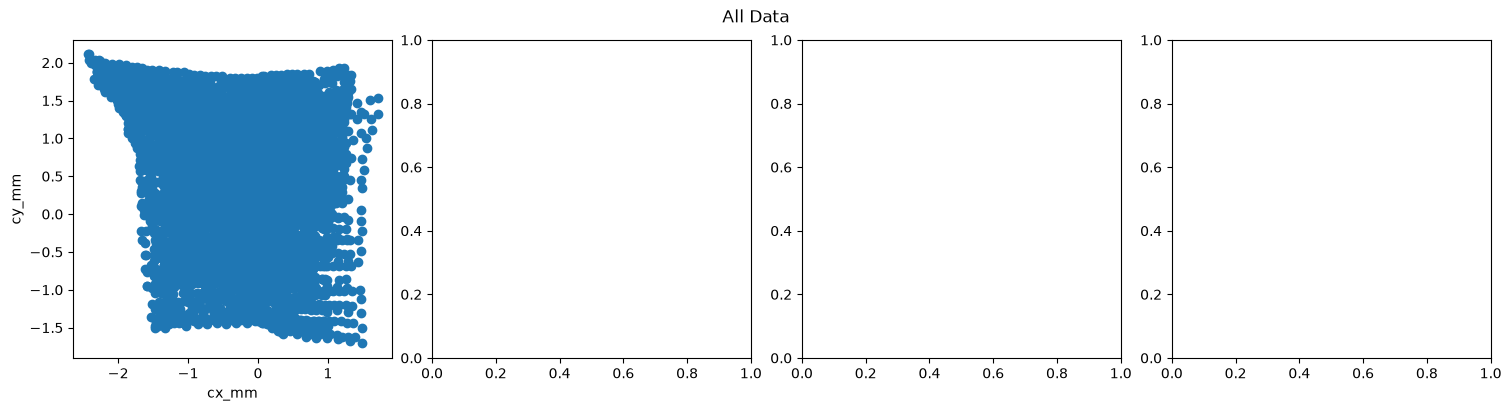

In [178]:
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_list = [data_3]

fig, axs = plt.subplots(1, 4, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2> Remove NaNs

In [179]:
all_data = data_3.dropna()

data_3.Name = "data_3"

<h2> Create StandardScalers based on all data

In [180]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

<h2>Scale all datasets

In [181]:
X_scaled = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled = scalerY.transform(all_data[["s0", "s1", "s2"]])

<h2> Build Model

In [182]:
model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1])
model.summary() #investigate

Model: "sequential_40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_119 (Dense)               │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_120 (Dense)               │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_121 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_122 (Dense)               │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,531 (25.51 KB)

 Trainable params: 6,531 (25.51 KB)

 Non-trainable params: 0 (0.00 B)

<h1> Training on data_1 - 16thOct

<h2>TimeSeriesSplit

In [183]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

In [184]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        restore_best_weights=True
    )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    callbacks=callbacks)
    print(patience)
    return history

Fold 0:
  Train: index=0 to 966 
  Test:  index=967 to 1933
3

Fold: 0 Results (scaled):
  Overall R2:  0.9165
  Weighted R2: 0.9232
Fold 1:
  Train: index=0 to 1933 
  Test:  index=1934 to 2900
3

Fold: 1 Results (scaled):
  Overall R2:  0.7998
  Weighted R2: 0.7838
Fold 2:
  Train: index=0 to 2900 
  Test:  index=2901 to 3867
3

Fold: 2 Results (scaled):
  Overall R2:  0.8926
  Weighted R2: 0.9052
MSE scores for each fold: [0.04985662177205086, 0.1564280390739441, 0.08521874994039536]


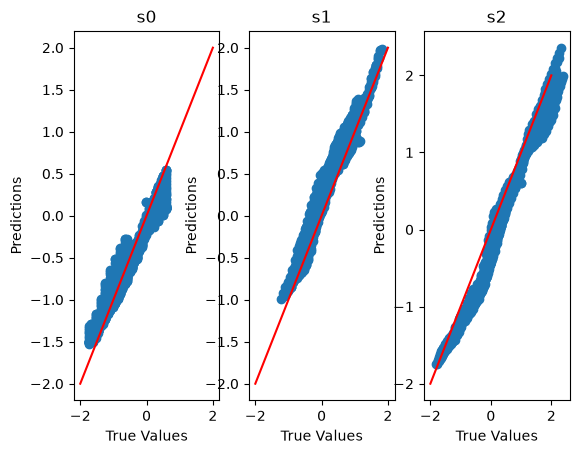

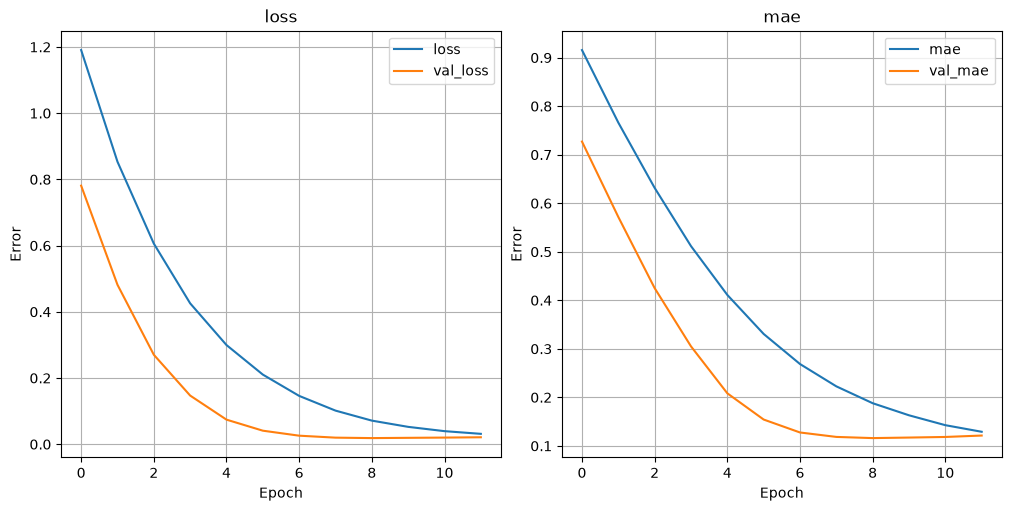

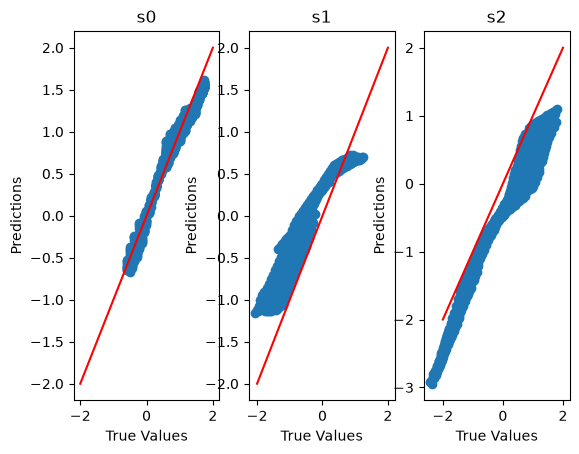

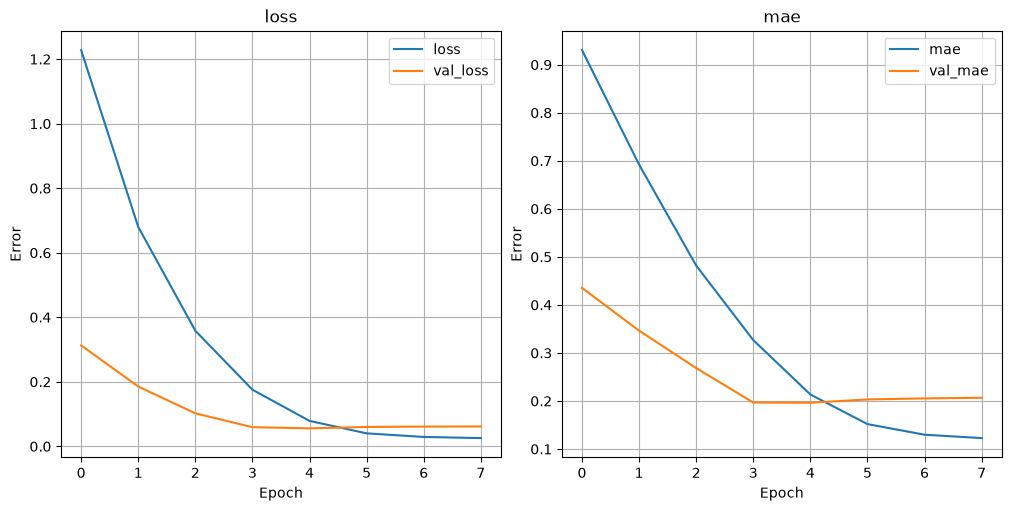

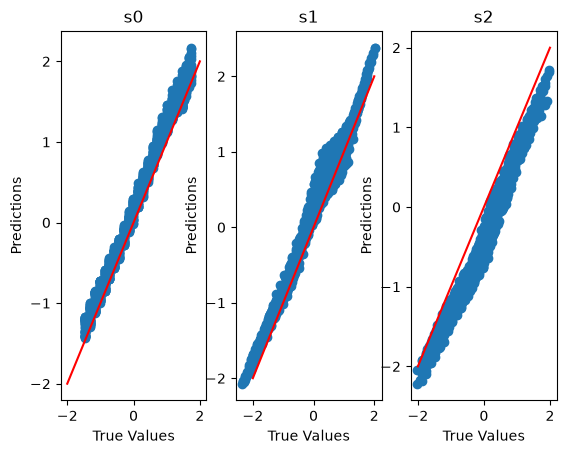

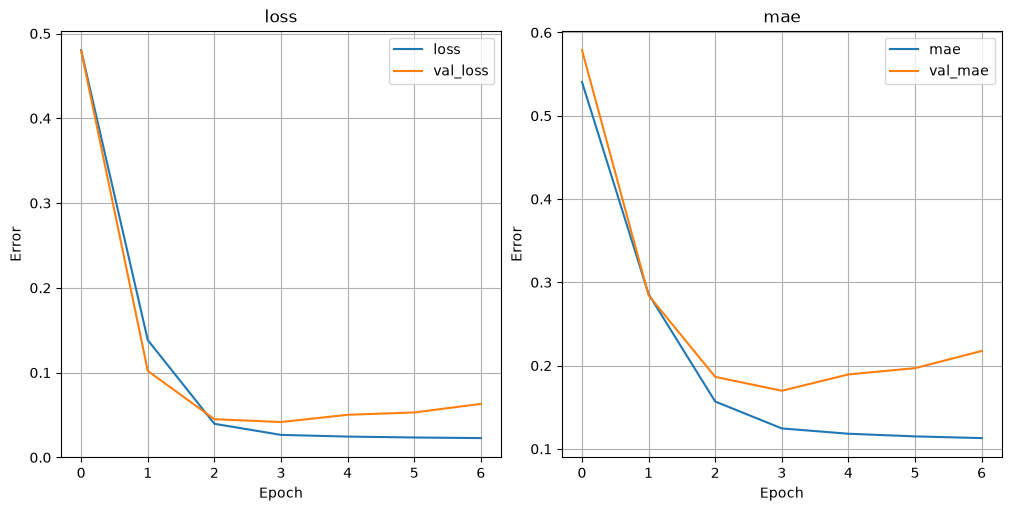

In [185]:
# model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1])

scores = []

X = X_scaled
y = y_scaled

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1]) #instantiate new model each time to see difference

    history = train_model(model, X_train, y_train, verbose=0, epochs=50, patience=3)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)

print("MSE scores for each fold:", scores)

In [186]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test)

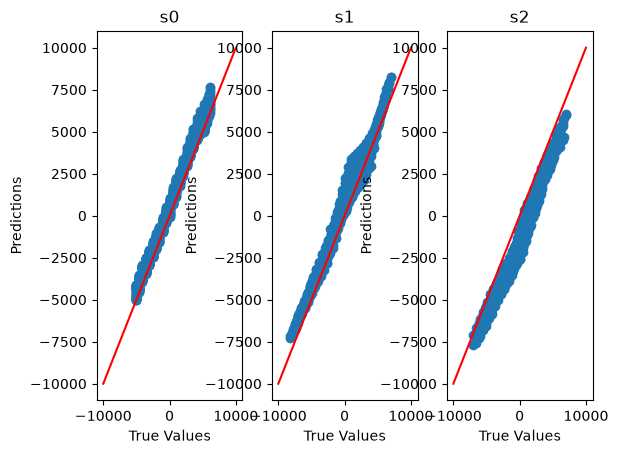

In [187]:
plot_motors(y_test_inverse, y_pred_inverse, [-10000,10000])

In [ ]:
#finding data that needs fixing 
y_pred_df = pd.DataFrame(y_pred_inverse)

y_pred_df["s0_true"] = y_test_inverse[:,0]
y_pred_df["s1_true"] = y_test_inverse[:,1]
y_pred_df["s2_true"] = y_test_inverse[:,2]

y_pred_df["s0_diff"] = y_pred_df["s0_true"] - y_pred_df[0]
y_pred_df["s1_diff"] = y_pred_df["s1_true"] - y_pred_df[1]
y_pred_df["s2_diff"] = y_pred_df["s2_true"] - y_pred_df[2]
print(y_pred_df.index[y_pred_df["s1_diff"] == max(y_pred_df["s1_diff"])])
print(y_pred_df.index[y_pred_df["s2_diff"] == max(y_pred_df["s2_diff"])])
y_pred_df

,0,1,2,s0_true,s1_true,s2_true,s0_diff,s1_diff,s2_diff
0,5181.985352,-6125.113770,1562.734009,4.096000e+03,-6925.000000,2829.000000,-1085.985352,-799.886230,1266.265991
1,5250.966309,-6393.968750,1817.800415,4.096000e+03,-7146.999512,3051.000000,-1154.966309,-753.030762,1233.199585
2,5319.947266,-6662.823242,2072.867432,4.096000e+03,-7369.000000,3273.000000,-1223.947266,-706.176758,1200.132568
3,5571.873047,-6770.653320,1973.368042,4.352000e+03,-7497.000488,3145.000000,-1219.873047,-726.347168,1171.631958
4,5493.251953,-6651.527344,1903.594238,4.352000e+03,-7275.000000,2923.000000,-1141.251953,-623.472656,1019.405762
...,...,...,...,...,...,...,...,...,...
962,6296.157227,-5071.661133,-1112.596558,5.120000e+03,-6107.000000,987.000061,-1176.157227,-1035.338867,2099.596680
963,6446.199219,-5519.852539,-579.513550,5.120000e+03,-6551.000000,1431.000000,-1326.199219,-1031.147461,2010.513550
964,6626.842773,-5934.514648,-113.346275,5.120000e+03,-6994.000000,1874.000122,-1506.842773,-1059.485352,1987.346436
965,539.727783,1190.042480,-2214.294922,9.536743e-07,0.000000,0.000000,-539.727783,-1190.042480,2214.294922
